# 01 · Exploring Istanbul's hourly traffic (IBB open data, 2024)

Each record is one **geohash-6 cell** (≈ 1.2 km × 0.6 km) in one hour, with the average, minimum and maximum speed and the number of vehicles seen by the navigation data source. The questions are: how regular is traffic, and what breaks the regularity?

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from istanbul_traffic import plots
from istanbul_traffic.calendar import calendar_features

plots.apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
metrics = json.loads(Path("reports/metrics.json").read_text())
panel = pd.read_parquet("data/processed/panel.parquet")
cal = calendar_features(pd.DatetimeIndex(panel["date_time"].unique()))
panel = panel.join(cal, on="date_time")
cat = pd.read_csv("reports/cell_catalogue.csv", index_col=0)

## Coverage & data quality

In [2]:
d = metrics["data"]
print(
    f"cells in the city: {d['cells_total']:,} | modelled: {d['cells_modelled']} (busiest with >= 97 % hourly coverage)"
)
print(
    f"panel rows (cell x hour): {d['panel_rows']:,} | missing target: {d['missing_target_share']:.1%}"
)
pd.Series(d["hours_with_data_by_month"], name="share of hours with data").to_frame().T

cells in the city: 2,464 | modelled: 150 (busiest with >= 97 % hourly coverage)
panel rows (cell x hour): 2,631,600 | missing target: 7.7%


,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,...,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
share of hours with data,0.993,1.000,0.961,0.951,0.911,0.942,0.942,0.871,0.968,0.891,...,0.985,0.985,0.935,0.900,1.000,0.969,1.000,1.000,1.000,0.716


The source has gaps. **January 2024 is missing 12 days** (55 % of hours present) and **December 2024 has only 72 %** of its hours; several 2023 months sit around 87–90 %. Missing hours stay as `NaN` in the panel. They are never imputed and never used as training targets, and lag features that point into a gap are simply missing (LightGBM handles that natively). The 10 test weeks are almost complete (≥ 95 % of cell-hours), except the Kurban Bayramı week, where the source is missing one day (14 June).

## Where is the morning peak worst?

![map](../reports/figures/congestion_map.png)

In [3]:
top = cat[cat["coverage"] >= 0.5].nlargest(8, "congestion_index")[
    ["latitude", "longitude", "free_flow_speed", "rush_speed", "congestion_index"]
]
top

,latitude,longitude,free_flow_speed,rush_speed,congestion_index
geohash,,,,,
sxk9f8,41.092,28.943,92.545,26.713,0.711
sxk9w9,41.053,29.119,96.385,29.876,0.690
sxk9qw,41.037,29.119,95.512,31.326,0.672
sxk3t3,41.053,28.713,82.369,27.979,0.660
sxkb99,40.877,29.251,68.397,23.325,0.659
sxk9n4,40.971,29.097,76.483,26.212,0.657
sxk3rx,41.042,28.812,75.669,27.271,0.640
sxk9n2,40.960,29.108,74.990,27.394,0.635


Congestion index = 1 − (school-day 07–10 h speed / night-time speed). The night speed is a standard proxy for free-flow speed.

## Daily and weekly rhythm

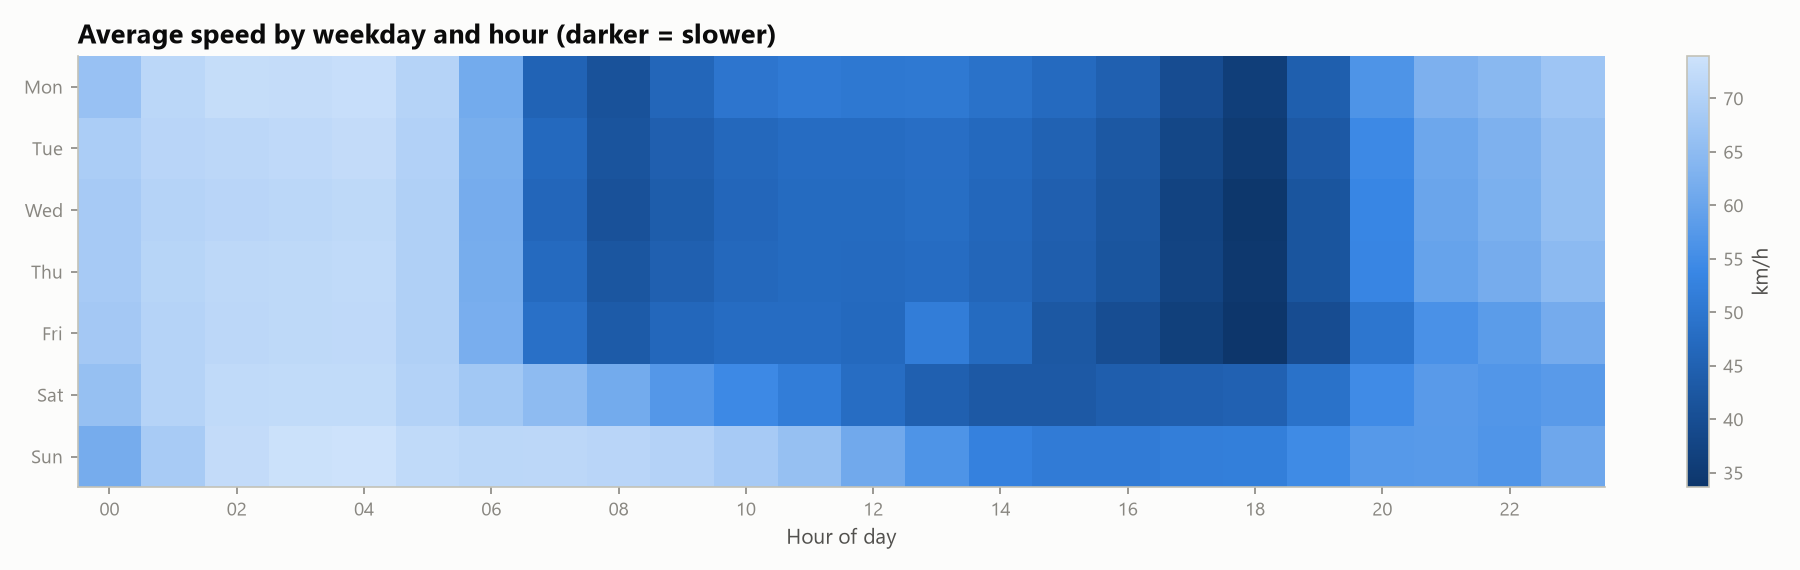

In [4]:
plots.hour_dow_heatmap(panel[panel["is_holiday"] == 0], "reports/figures/speed_hour_weekday.png")
from IPython.display import Image

display(Image("reports/figures/speed_hour_weekday.png"))

Two clear weekday peaks appear: **08:00** and an even slower **17:00–19:00**. Weekends shift to a single afternoon peak. There is also a noticeable **lighter slot around 13:00 on Fridays**, most likely linked to Friday prayers (an interpretation, not tested here).

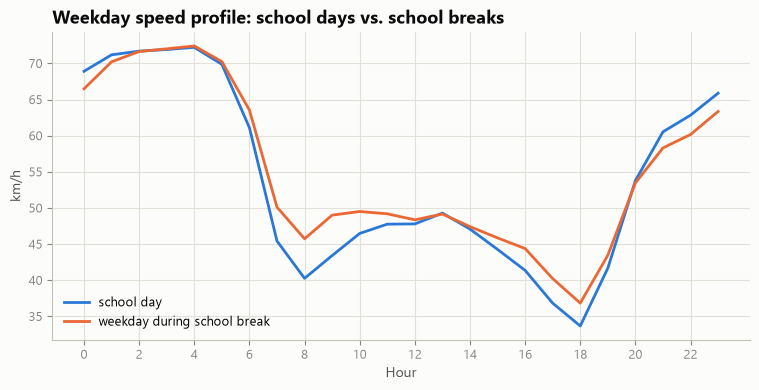

08:00  school day 40.3 km/h | school break 45.7 km/h (+14%)
18:00  school day 33.7 km/h | school break 36.8 km/h (+9%)


In [5]:
wk = panel[(panel["is_weekend"] == 0) & (panel["is_holiday"] == 0)]
prof = wk.groupby(["hour", "school_day"])["average_speed"].mean().unstack()
prof.columns = ["school break", "school day"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(prof.index, prof["school day"], color=plots.SERIES[0], label="school day")
ax.plot(
    prof.index, prof["school break"], color=plots.SERIES[1], label="weekday during school break"
)
ax.set_xticks(range(0, 24, 2))
ax.legend(loc="lower left")
ax.set(title="Weekday speed profile: school days vs. school breaks", xlabel="Hour", ylabel="km/h")
plt.show()
for h in (8, 18):
    print(
        f"{h:02d}:00  school day {prof.loc[h, 'school day']:.1f} km/h | school break {prof.loc[h, 'school break']:.1f} km/h "
        f"(+{prof.loc[h, 'school break'] / prof.loc[h, 'school day'] - 1:.0%})"
    )

## Holidays break the weekly pattern

![daily](../reports/figures/daily_profile_2024.png)

In [6]:
day = (
    panel.set_index("date_time")
    .resample("D")
    .agg({"number_of_vehicles": "sum", "average_speed": "mean"})
)
dcal = calendar_features(day.index)
normal = day[(dcal["is_holiday"] == 0) & (dcal["is_weekend"] == 0) & (dcal["school_day"] == 1)]
for name, dates in {
    "Ramazan Bayramı": ["2024-04-10", "2024-04-11", "2024-04-12"],
    "Kurban Bayramı": ["2024-06-16", "2024-06-17", "2024-06-18", "2024-06-19"],
    "Republic Day": ["2024-10-29"],
}.items():
    sub = day.loc[pd.to_datetime(dates)]
    print(
        f"{name:16s} vehicles {sub['number_of_vehicles'].mean() / normal['number_of_vehicles'].mean() - 1:+.0%} | "
        f"speed {sub['average_speed'].mean() / normal['average_speed'].mean() - 1:+.0%} vs. a normal school day"
    )

Ramazan Bayramı  vehicles -35% | speed +10% vs. a normal school day
Kurban Bayramı   vehicles -35% | speed +23% vs. a normal school day
Republic Day     vehicles -7% | speed +14% vs. a normal school day


* **School calendar:** on weekdays during school breaks the 08:00 peak is **14 % faster** and the 18:00 peak 9 % faster. School runs are a large part of Istanbul's morning congestion.
* **Bayrams:** traffic volume drops by about **35 %** and speeds rise (+10 % Ramazan, +23 % Kurban). National holidays such as Republic Day have a much smaller effect on volume.

**Why this matters for forecasting:** a "same hour last week" forecast is excellent on ordinary weeks and badly wrong during and right after a Bayram. Holidays follow the lunar calendar and move about 11 days earlier every year, so a model has to be told about them explicitly. That is what the calendar features do.